# 08 -- Ensemble models (bagging: random forest, extra trees)

Bagging ensembles average many de-correlated trees to cut the variance
of a single tree. This notebook tunes a random forest and compares it to
extremely randomised trees.

1. `GridSearchCV` over forest size, depth, feature subsampling, leaf size.
2. **Loss curve** vs number of trees (warm-start growth).
3. Holdout evaluation, model comparison, and feature importance.

The forests parallelise internally (`n_jobs=-1`), so GridSearchCV runs
with `n_jobs=1` to avoid CPU oversubscription.

In [1]:
from __future__ import annotations

import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.modeling import (
    classification_metrics,
    cv_results_frame,
    evaluate_split,
    load_modeling_data,
    make_pipeline,
    metrics_frame,
    run_grid_search,
    subsample,
    train_valid_report,
)
from src.modeling import plots

data = load_modeling_data()
pd.Series(data.summary())


n_train                246005.0000
n_holdout               61502.0000
n_features                 52.0000
train_target_rate           0.0807
holdout_target_rate         0.0807
n_folds                     5.0000
pos_weight                 11.3900
dtype: float64

In [2]:
# Fraction of the TRAIN partition used for GridSearchCV. The holdout is never
# touched during tuning. Lower this (e.g. 0.3) for faster iteration, then set
# back to 1.0 to confirm the final model on the full training data.
SEARCH_FRAC = 0.3
search = subsample(data, frac=SEARCH_FRAC)
pd.Series(search.summary())


n_train                73802.0000
n_holdout              61502.0000
n_features                52.0000
train_target_rate          0.0807
holdout_target_rate        0.0807
n_folds                    5.0000
pos_weight                11.3900
dtype: float64

## Hyperparameter search (random forest)

In [3]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=42, n_jobs=-1)
param_grid = {
    "n_estimators": [300, 500],
    "max_depth": [8, 12, None],
    "max_features": ["sqrt", 0.5],
    "min_samples_leaf": [20, 50],
    "class_weight": ["balanced", "balanced_subsample"],
}
gs = run_grid_search(rf, param_grid, search, refit="roc_auc", n_jobs=1)
cv_results_frame(gs).head(10)

Fitting 48 candidate(s) x 5 folds ...
Fitting 5 folds for each of 48 candidates, totalling 240 fits
Done in 19292.1s. Best roc_auc=0.7581
Best params: {'model__class_weight': 'balanced_subsample', 'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 20, 'model__n_estimators': 500}


,param_model__class_weight,param_model__max_depth,param_model__max_features,param_model__min_samples_leaf,param_model__n_estimators,mean_train_roc_auc,mean_test_roc_auc,std_test_roc_auc,rank_test_roc_auc
0,balanced_subsample,None,sqrt,20,500,0.972239,0.758087,0.005661,1
1,balanced,None,sqrt,20,500,0.972360,0.758034,0.005711,2
2,balanced,None,sqrt,20,300,0.971943,0.757574,0.005839,3
3,balanced_subsample,None,sqrt,20,300,0.971841,0.757433,0.005734,4
4,balanced_subsample,None,sqrt,50,500,0.903932,0.757429,0.006013,5
5,balanced_subsample,None,sqrt,50,300,0.903441,0.757404,0.006132,6
6,balanced,None,sqrt,50,500,0.903803,0.757163,0.005621,7
7,balanced,None,sqrt,50,300,0.903514,0.757141,0.005822,8
8,balanced_subsample,12,sqrt,50,500,0.874336,0.756172,0.005909,9
9,balanced,12,sqrt,50,500,0.874539,0.755951,0.006197,10


## Loss curve vs number of trees

Grow a warm-start forest and record train/validation log loss as trees
are added. Validation loss falls then plateaus - more trees reduce
variance without overfitting.

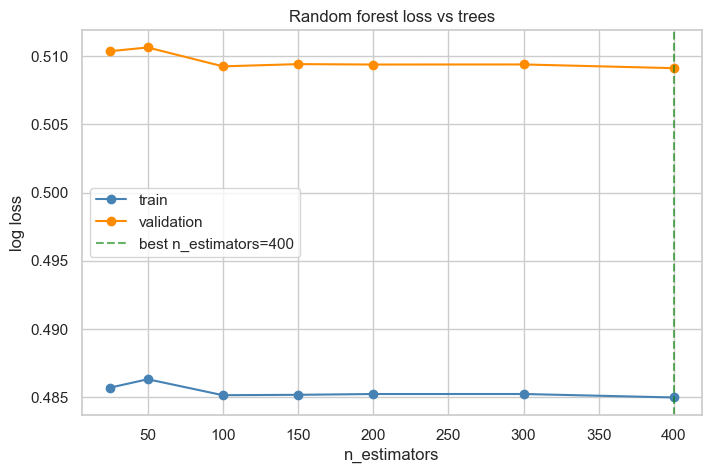

In [4]:
from src.modeling.curves import warm_start_loss_curve
from sklearn.ensemble import RandomForestClassifier

n_range = [25, 50, 100, 150, 200, 300, 400]
rf_curve = RandomForestClassifier(
    max_depth=12, min_samples_leaf=50, max_features="sqrt",
    class_weight="balanced", random_state=42, n_jobs=-1,
)
tr, va = warm_start_loss_curve(
    rf_curve, n_range, search.X_train, search.y_train, data.X_holdout, data.y_holdout
)
plots.plot_param_loss_curve(n_range, tr, va, xlabel="n_estimators", title="Random forest loss vs trees")
plt.show()

## CV validation and learning curves

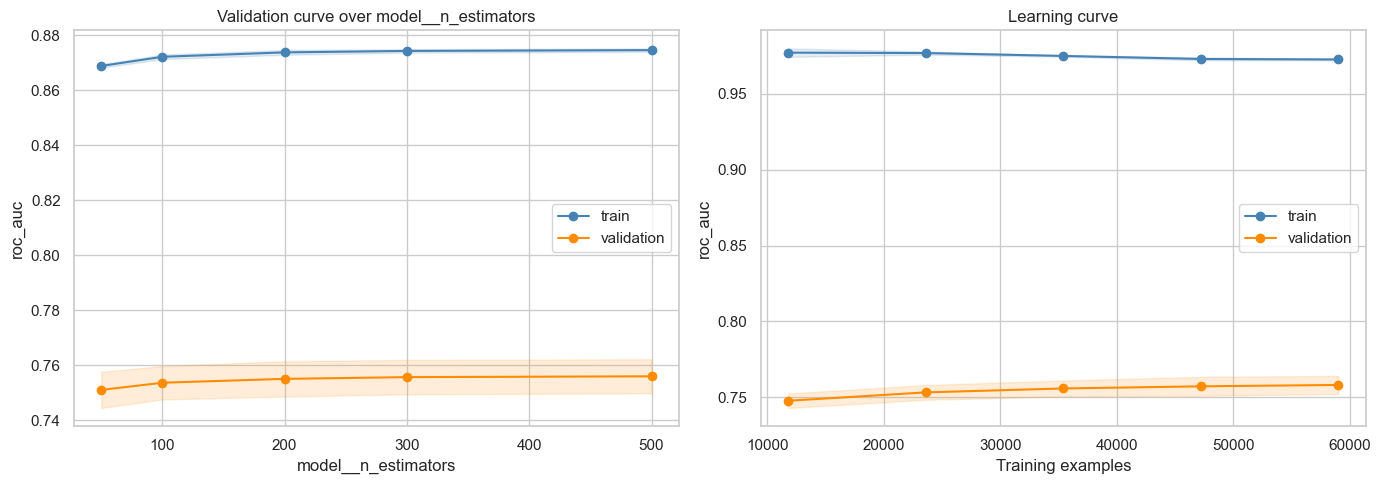

In [5]:
from sklearn.ensemble import RandomForestClassifier

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plots.plot_validation_curve(
    make_pipeline(RandomForestClassifier(
        max_depth=12, min_samples_leaf=50, max_features="sqrt",
        class_weight="balanced", random_state=42, n_jobs=-1)),
    search.X_train, search.y_train,
    param_name="model__n_estimators",
    param_range=[50, 100, 200, 300, 500],
    cv=search.cv, n_jobs=1, ax=axes[0],
)
plots.plot_learning_curve(gs.best_estimator_, search.X_train, search.y_train, cv=search.cv, n_jobs=1, ax=axes[1])
plt.tight_layout()
plt.show()

## Compare random forest vs extra trees

In [6]:
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier

rf_best = gs.best_estimator_
et = make_pipeline(ExtraTreesClassifier(
    n_estimators=400, max_depth=12, min_samples_leaf=50, max_features="sqrt",
    class_weight="balanced", random_state=42, n_jobs=-1))
et.fit(search.X_train, search.y_train)

rows = {
    "random_forest": evaluate_split(rf_best, data.X_holdout, data.y_holdout),
    "extra_trees": evaluate_split(et, data.X_holdout, data.y_holdout),
}
metrics_frame(rows).round(4)

,roc_auc,gini,ks,pr_auc,log_loss,brier,best_f1,best_f1_threshold
random_forest,0.7600,0.5201,0.4011,0.2403,0.3920,0.1165,0.3059,0.45
extra_trees,0.7565,0.5129,0.3907,0.2398,0.5929,0.2020,0.3008,0.55


## Holdout evaluation (random forest)

In [7]:
# Train vs holdout metrics for the selected model (overfitting check)
report = train_valid_report(gs.best_estimator_, data, valid_as_holdout=True)
report.round(4)


,roc_auc,gini,ks,pr_auc,log_loss,brier,best_f1,best_f1_threshold
train,0.8282,0.6564,0.5083,0.3909,0.3726,0.1083,0.4194,0.50
holdout,0.7600,0.5201,0.4011,0.2403,0.3920,0.1165,0.3059,0.45


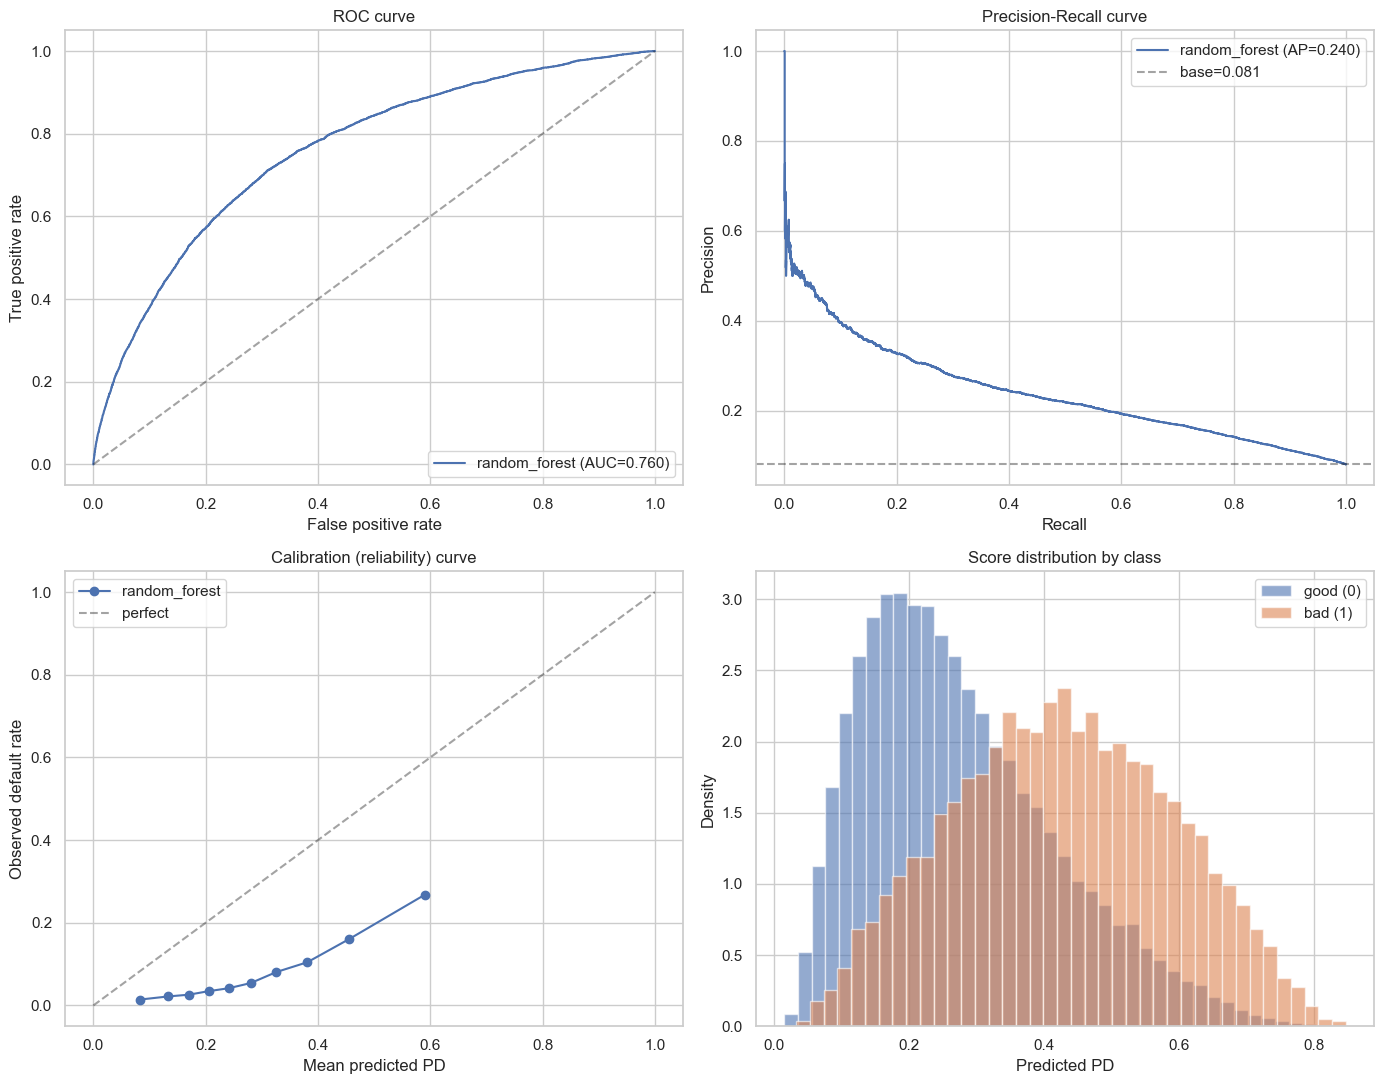

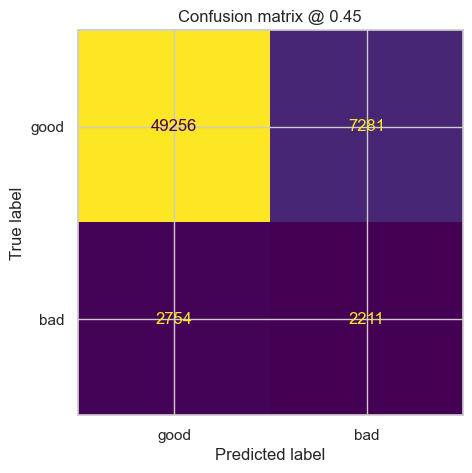

In [8]:
# Holdout diagnostics for the selected model
best = gs.best_estimator_
proba_ho = best.predict_proba(data.X_holdout)[:, 1]

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
plots.plot_roc_pr(data.y_holdout.to_numpy(), proba_ho, label="random_forest", axes=axes[0])
plots.plot_calibration(data.y_holdout.to_numpy(), proba_ho, ax=axes[1][0], label="random_forest")
plots.plot_score_distribution(data.y_holdout.to_numpy(), proba_ho, ax=axes[1][1])
plt.tight_layout()
plt.show()

best_t = classification_metrics(data.y_holdout.to_numpy(), proba_ho)["best_f1_threshold"]
fig, ax = plt.subplots(figsize=(5, 5))
plots.plot_confusion(data.y_holdout.to_numpy(), proba_ho, threshold=best_t, ax=ax)
plt.show()


## Feature importance

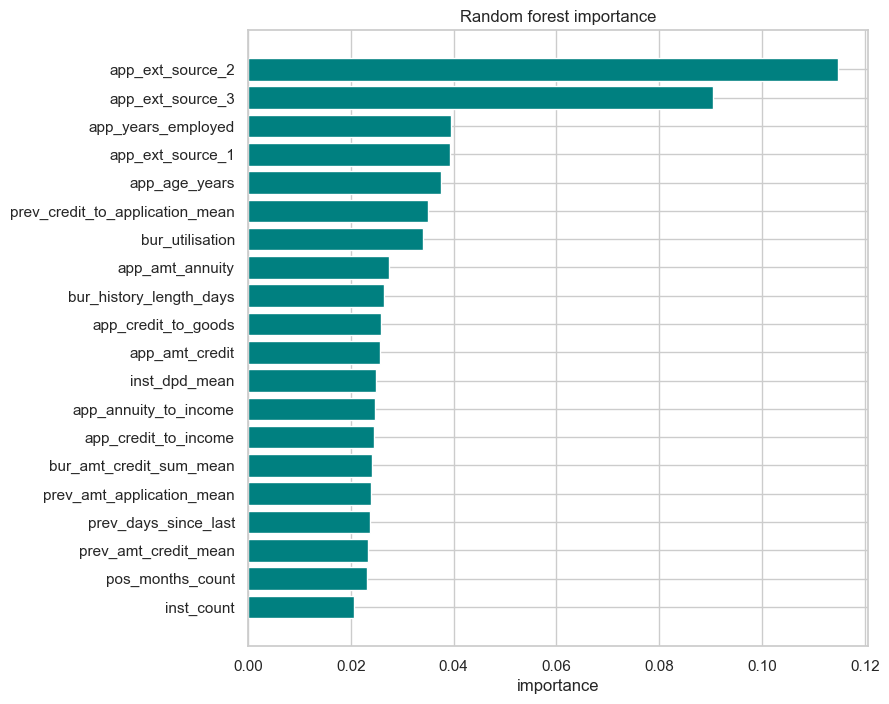

In [9]:
# Feature importance for the selected model
pre = gs.best_estimator_.named_steps["preprocess"]
feat_names = list(pre.transform(search.X_train.iloc[:1]).columns)
model = gs.best_estimator_.named_steps["model"]
importances = getattr(model, "feature_importances_", None)
if importances is not None:
    fig, ax = plt.subplots(figsize=(8, 8))
    plots.plot_feature_importance(feat_names, importances, top=20, ax=ax, title="Random forest importance")
    plt.show()


## Takeaways

- The forest sharply reduces single-tree variance; validation loss
  plateaus once enough trees are added.
- Random forest and extra trees are close; both are strong baselines
  before gradient boosting.